# Pipeline final: agua de lluvia en Lima Sur por cambio de radar (NISAR)
### Evento del 5 de noviembre de 2026 · U-Net (4 codificadores + ensamble) + ML clásico · exporta GeoTIFF para los mapas

**Idea:** comparar la imagen tomada **justo después de la lluvia** con la imagen "normal" de la misma zona, que es la mediana de los **días secos de la misma órbita**. Lo que se oscurece mucho es candidato a agua de lluvia.

| Evento | Lluvia | Pase NISAR | Órbita | Uso |
|---|---|---|---|---|
| **5 nov 2026** | 4 nov 16:00 → 5 nov 06:00, 10.4 mm en VMT (récord, 65 puntos de aniego) | 5 nov, 5:58 am (~0 h) | 003 A | **evento principal** (entrenamiento y prueba en zonas no vistas) |
| 18 ago 2026 | 16–17 ago (aniegos en VES, VMT, SJM y Chorrillos) | 18 ago, 6:25 pm (~2 días) | 083 D | prueba en otro evento |
| 12 oct 2026 y 13 jul 2026 | días secos | — | 003 / 083 | **control**: el modelo debería detectar casi nada |

**Partes del notebook**
1. **Viabilidad:** ¿cambió el radar en los lugares que reportó la prensa más que en el resto de la ciudad y más que en un día seco?
2. **Etiqueta automática (regla):** caída de HH respecto a 5 días secos, en terreno plano, sin agua permanente ni zonas siempre oscuras.
3. **Modelos:** reciben **solo la imagen del evento y una imagen seca previa**, como en un mapeo rápido real. La regla, en cambio, usa 5 días secos. Así el modelo no puede "copiar" la regla y tiene que aprender a reconocer el cambio con menos información.
4. **Pruebas:** zonas no vistas del 5 de noviembre, el 18 de agosto, días secos de control y lugares de la prensa.

**Kaggle:** agrega el dataset `andres4499/dataaaaaaaa` y activa **GPU** e **Internet**. Corre en unos 40–70 min con GPU (en CPU, unas 5 horas). Al final guarda los GeoTIFF en `final/geotiff/`, que lee el notebook de mapas interactivos.

In [1]:
# ============ CONFIGURACIÓN ============
RAPIDO = False
ENCODERS = ["resnet34", "efficientnet-b0", "mobilenet_v2", "vgg19_bn"]
EPOCAS = 4 if RAPIDO else 25
PACIENCIA = 5
MIN_EPOCAS = 8                 # la U-Net no se detiene antes de esta época
LOTE = 16
SEMILLA = 0
REGION = (-77.06, -12.30, -76.83, -12.05)        # Lima Sur ampliada (lon_min, lat_min, lon_max, lat_max)
LIMA_SUR = (-77.02, -12.28, -76.86, -12.10)      # recuadro para mapas y métricas finales

# Días secos de referencia por órbita (sin lluvia reportada). El 24 oct NO se usa: hubo lloviznas del 23 al 25 de octubre.
SECOS = {"003": ["20251029", "20260825", "20260906", "20260930", "20261012"],
         "083": ["20251103", "20251127", "20260701", "20260713", "20260725", "20260830", "20261017"]}
EVENTO = {"fecha": "20261105", "orbita": "003"}
OTRO_EVENTO = {"fecha": "20260818", "orbita": "083"}
CONTROLES = [{"fecha": "20261012", "orbita": "003"}, {"fecha": "20260713", "orbita": "083"}]

# Regla de cambio
CAIDA_DB = -3.0          # caída mínima respecto a la mediana seca
Z_MIN = -2.0             # y al menos 2 desviaciones de la variabilidad normal del píxel
PENDIENTE_MAX = 5.0      # grados
OSCURO_SIEMPRE = -18.0   # zonas que ya son muy oscuras en días secos (sombras, agua, pistas lisas): se excluyen

# Lugares reportados por la prensa (aniegos en el 5 nov y/o 16-18 ago)
NOTICIAS = [("Baipás Nueva Esperanza (Pachacútec)", -12.1804, -76.9435),
            ("VES Sector 1 Grupo 1", -12.1874, -76.9471),
            ("VMT José Gálvez", -12.2244, -76.9029),
            ("Hospital de Emergencias VES", -12.2321, -76.9348)]

In [2]:
import importlib.util, subprocess, sys
faltan = [p for m, p in [("segmentation_models_pytorch", "segmentation-models-pytorch"), ("rasterio", "rasterio"),
                         ("xgboost", "xgboost")] if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)

import os, gc, glob, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rasterio, torch, segmentation_models_pytorch as smp
from rasterio.windows import Window
from rasterio.warp import transform as transformar_coord
from rasterio.transform import rowcol
from scipy import ndimage
from torch.utils.data import Dataset, DataLoader
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import xgboost as xgb
warnings.filterwarnings("ignore")
np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
ENTRADA = os.environ.get("ENTRADA_KAGGLE", "/kaggle/input")
SALIDA = Path("/kaggle/working/final") if Path("/kaggle/working").exists() else Path("salida_final")
for s in ["", "figuras", "tablas", "modelos"]:
    (SALIDA / s).mkdir(parents=True, exist_ok=True)
PROC = Path(sorted(glob.glob(f"{ENTRADA}/**/procesado/nisar/lima/hh_*.tif", recursive=True))[0]).parent.parents[1]
LIMA = PROC / "nisar/lima"
FECHAS = sorted(p.stem[3:] for p in LIMA.glob("hh_*.tif"))
print("datos:", LIMA, "| dispositivo:", DISPOSITIVO)
print("fechas disponibles:", FECHAS)

datos: /kaggle/input/datasets/andres4499/dataaaaaaaa/Data/procesado/nisar/lima | dispositivo: cuda
fechas disponibles: ['20251029', '20251103', '20251127', '20260114', '20260701', '20260713', '20260725', '20260818', '20260825', '20260830', '20260906', '20260930', '20261005', '20261012', '20261017', '20261024', '20261105']


## 1. Cargar la región (Lima Sur ampliada) y alinear niveles

In [3]:
with rasterio.open(LIMA / f"hh_{FECHAS[0]}.tif") as f:
    PERFIL = f.profile
RES = abs(PERFIL["transform"].a)

def ventana(caja, perfil=PERFIL):
    o, s, e, n = caja
    xs, ys = transformar_coord("EPSG:4326", perfil["crs"], [o, e], [n, s])
    (f0, f1), (c0, c1) = rowcol(perfil["transform"], xs, ys)
    return max(f0, 0), min(f1, perfil["height"]), max(c0, 0), min(c1, perfil["width"])

F0, F1, C0, C1 = ventana(REGION)
VEN = Window(C0, F0, C1 - C0, F1 - F0)
TRANSF = PERFIL["transform"] * rasterio.Affine.translation(C0, F0)
H, W = F1 - F0, C1 - C0
s0, s1, c0_, c1_ = ventana(LIMA_SUR)
SUR = np.s_[max(s0 - F0, 0):min(s1 - F0, H), max(c0_ - C0, 0):min(c1_ - C0, W)]
print(f"región: {H} x {W} píxeles de {RES:.0f} m ({H * W * RES ** 2 / 1e6:.0f} km²)")

def leer_tif(nombre, dtype="float32"):
    with rasterio.open(LIMA / nombre) as f:
        return f.read(1, window=VEN).astype(dtype)

def suave(hh, n=5):
    v = np.isfinite(hh)
    lin = ndimage.uniform_filter(np.where(v, 10 ** (hh / 10), 0).astype("float32"), n)
    peso = ndimage.uniform_filter(v.astype("float32"), n)
    return np.where(v, 10 * np.log10(lin / np.maximum(peso, 1e-6) + 1e-10), np.nan).astype("float32")

WC = leer_tif("worldcover.tif", "uint8")
PERM = WC == 80
URBANO = WC == 50
if (LIMA / "dem.tif").exists():
    dem = leer_tif("dem.tif")
    gy, gx = np.gradient(np.nan_to_num(dem), RES)
    PLANO = np.degrees(np.arctan(np.hypot(gx, gy))) < PENDIENTE_MAX
    del dem, gx, gy
else:
    print("[aviso] no hay dem.tif: no se aplica el filtro de pendiente")
    PLANO = np.ones((H, W), bool)

S = {}
necesarias = set([EVENTO["fecha"], OTRO_EVENTO["fecha"]] + [c["fecha"] for c in CONTROLES] + sum(SECOS.values(), []))
for fch in sorted(necesarias):
    if fch in FECHAS:
        S[fch] = suave(leer_tif(f"hh_{fch}.tif"))
    else:
        print("[aviso] falta hh_", fch)
for o in SECOS:
    SECOS[o] = [f for f in SECOS[o] if f in S]
print("días secos disponibles:", SECOS)
print(f"urbano {URBANO.mean():.0%} | plano {PLANO.mean():.0%} | agua permanente {PERM.mean():.0%}")

región: 5496 x 5046 píxeles de 5 m (693 km²)
días secos disponibles: {'003': ['20251029', '20260825', '20260906', '20260930', '20261012'], '083': ['20251103', '20251127', '20260701', '20260713', '20260725', '20260830', '20261017']}
urbano 37% | plano 60% | agua permanente 24%


In [4]:
def referencia(orbita, excluir=None):
    # mediana y variabilidad de los días secos de la órbita, con niveles alineados
    fechas = [f for f in SECOS[orbita] if f != excluir]
    assert fechas, f"no hay días secos para la órbita {orbita}"
    pila = np.stack([S[f] for f in fechas])
    med0 = np.nanmedian(pila, 0)
    tierra = ~PERM & np.isfinite(med0)
    for k in range(len(pila)):
        ok = tierra & np.isfinite(pila[k])
        pila[k] -= np.median((pila[k] - med0)[ok]) if ok.any() else 0
    med = np.nanmedian(pila, 0)
    sd = np.nanstd(pila, 0) if len(fechas) > 1 else np.full_like(med, np.nan)
    return med.astype("float32"), np.maximum(np.nan_to_num(sd, nan=1.5), 1.0).astype("float32"), fechas


def alinear(img, med):
    ok = ~PERM & np.isfinite(img) & np.isfinite(med)
    return img - np.median((img - med)[ok])


def regla(fecha, orbita, excluir=None):
    med, sd, fechas = referencia(orbita, excluir)
    ev = alinear(S[fecha], med)
    d = ev - med
    z = d / sd
    evaluable = np.isfinite(d) & PLANO & ~PERM & (med > OSCURO_SIEMPRE)
    agua = evaluable & (d < CAIDA_DB) & (z < Z_MIN)
    agua = ndimage.binary_opening(agua)
    lab, n = ndimage.label(agua)
    if n:
        tam = np.bincount(lab.ravel())
        agua = agua & (tam[lab] >= 10)
    sube = evaluable & URBANO & (d > -CAIDA_DB) & (z > -Z_MIN)
    et = np.full((H, W), 255, "uint8"); et[evaluable] = 0; et[agua] = 1
    return {"d": d.astype("float32"), "z": z.astype("float32"), "et": et, "sube": sube, "med": med, "fechas_ref": fechas}


def previa(fecha, orbita):
    antes = [f for f in SECOS[orbita] if f < fecha and f != fecha]
    return antes[-1] if antes else [f for f in SECOS[orbita] if f != fecha][0]


CASOS = {"evento": dict(EVENTO, excluir=None), "otro_evento": dict(OTRO_EVENTO, excluir=None)}
for c in CONTROLES:
    CASOS[f"control_{c['fecha']}"] = dict(c, excluir=c["fecha"])
R = {}
for nombre, c in list(CASOS.items()):
    if c["fecha"] not in S:
        print("se omite", nombre); CASOS.pop(nombre); continue
    R[nombre] = regla(c["fecha"], c["orbita"], c["excluir"])
    R[nombre]["previa"] = previa(c["fecha"], c["orbita"])
    et = R[nombre]["et"]
    print(f"{nombre:18s} {c['fecha']} | referencia: {len(R[nombre]['fechas_ref'])} días secos | imagen previa: {R[nombre]['previa']} "
          f"| agua por regla: {(et == 1).sum() * RES ** 2 / 1e6:.2f} km² ({(et == 1).sum() / max((et != 255).sum(), 1):.2%} de lo evaluable)")

evento             20261105 | referencia: 5 días secos | imagen previa: 20261012 | agua por regla: 3.54 km² (1.42% de lo evaluable)
otro_evento        20260818 | referencia: 7 días secos | imagen previa: 20260725 | agua por regla: 0.73 km² (0.30% de lo evaluable)
control_20261012   20261012 | referencia: 4 días secos | imagen previa: 20260930 | agua por regla: 1.26 km² (0.51% de lo evaluable)
control_20260713   20260713 | referencia: 6 días secos | imagen previa: 20260701 | agua por regla: 0.80 km² (0.32% de lo evaluable)


## 2. Viabilidad: ¿hay señal donde reportó la prensa?
Se compara el **cambio de HH** (evento − mediana seca, promediado en ~55 m) en los lugares reportados contra todos los píxeles urbanos,
para el evento y para un día seco de control. Si el evento no se distingue del control, la detección de cambio en intensidad no capta los aniegos.

,caso,fecha,% urbano con caída < -3 dB,% urbano con subida > +3 dB,% urbano marcado por la regla,cambio urbano mediano (dB)
0,evento,20261105,4.42,1.97,1.07,-0.49
1,otro_evento,20260818,1.82,2.05,0.19,-0.16
2,control_20261012,20261012,1.90,1.79,0.27,-0.02
3,control_20260713,20260713,2.33,2.91,0.22,-0.03


caso,control_20260713,control_20261012,evento,otro_evento
lugar,,,,
Baipás Nueva Esperanza (Pachacútec),18.8,50.8,67.5,1.4
Hospital de Emergencias VES,67.9,88.5,41.8,17.7
VES Sector 1 Grupo 1,89.1,29.2,57.8,97.2
VMT José Gálvez,95.9,9.2,29.4,68.5


Percentil bajo (<10) = el lugar se oscureció más que el 90 % de la ciudad (lo esperado para agua).


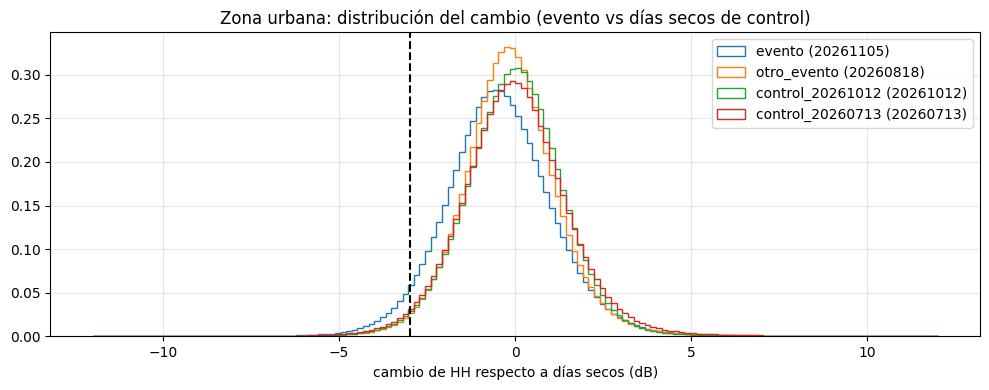

In [5]:
def a_pixel(lat, lon):
    x, y = transformar_coord("EPSG:4326", PERFIL["crs"], [lon], [lat])
    r, c = rowcol(TRANSF, x[0], y[0])
    return r, c

filas, res_urb = [], []
for nombre, r_ in R.items():
    dd = r_["d"].astype("float32")
    d = ndimage.uniform_filter(np.nan_to_num(dd), 11)
    urb = URBANO & np.isfinite(dd)
    du = d[urb]
    res_urb.append({"caso": nombre, "fecha": CASOS[nombre]["fecha"],
                    "% urbano con caída < -3 dB": 100 * np.mean(dd[urb] < CAIDA_DB),
                    "% urbano con subida > +3 dB": 100 * np.mean(dd[urb] > -CAIDA_DB),
                    "% urbano marcado por la regla": 100 * np.mean(r_["et"][urb] == 1),
                    "cambio urbano mediano (dB)": float(np.median(du))})
    for lugar, lat, lon in NOTICIAS:
        rr, cc = a_pixel(lat, lon)
        if 0 <= rr < H and 0 <= cc < W:
            v = d[rr, cc]
            filas.append({"caso": nombre, "lugar": lugar, "cambio (dB)": round(float(v), 2),
                          "percentil en la ciudad": round(100 * np.mean(du < v), 1),
                          "regla marca agua a <100 m": bool((R[nombre]["et"][max(rr - 20, 0):rr + 21, max(cc - 20, 0):cc + 21] == 1).any())})
VIAB_URB = pd.DataFrame(res_urb); VIAB_PUNTOS = pd.DataFrame(filas)
VIAB_URB.to_csv(SALIDA / "tablas/viabilidad_ciudad.csv", index=False)
VIAB_PUNTOS.to_csv(SALIDA / "tablas/viabilidad_noticias.csv", index=False)
display(VIAB_URB.round(2))
display(VIAB_PUNTOS.pivot_table(index="lugar", columns="caso", values="percentil en la ciudad"))
print("Percentil bajo (<10) = el lugar se oscureció más que el 90 % de la ciudad (lo esperado para agua).")

fig, ax = plt.subplots(figsize=(10, 4))
for nombre, r_ in R.items():
    du = r_["d"][URBANO & np.isfinite(r_["d"])]
    ax.hist(du, bins=150, range=(-12, 12), density=True, histtype="step", lw=2, label=f"{nombre} ({CASOS[nombre]['fecha']})")
ax.axvline(CAIDA_DB, color="k", ls="--"); ax.set_xlabel("cambio de HH respecto a días secos (dB)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Zona urbana: distribución del cambio (evento vs días secos de control)")
plt.tight_layout(); plt.savefig(SALIDA / "figuras/01_viabilidad_histograma.png", dpi=130); plt.show()

## 3. Datos para los modelos
- **Entrada:** HH del evento y HH de **una sola** imagen seca previa, de la misma órbita.
- **Etiqueta:** la regla con 5 días secos (1 = agua de lluvia, 0 = no, 255 = no evaluable).
- **División espacial** del evento del 5 de noviembre en bloques de 256 px: 60 % entrenamiento, 15 % validación (umbral y parada temprana) y 25 % prueba (zonas nunca vistas).

In [6]:
def entrada(nombre):
    c = CASOS[nombre]; r_ = R[nombre]
    ev = alinear(S[c["fecha"]], r_["med"]); pre = alinear(S[r_["previa"]], r_["med"])
    return np.stack([ev, pre]).astype("float32")

X = {n: entrada(n) for n in R}
FONDO = {n: X[n][0][SUR].astype("float16") for n in R}
for n in R:
    R[n]["d"] = R[n]["d"].astype("float16")
    for k in ("z", "med"):
        R[n].pop(k, None)
del S; gc.collect()
bi, bj = np.meshgrid(np.arange(H) // 256, np.arange(W) // 256, indexing="ij")
BLOQUE = (bi * 7 + bj * 3) % 20
PARTE = np.where(BLOQUE < 12, "train", np.where(BLOQUE < 15, "val", "test"))
et = R["evento"]["et"]
for p in ["train", "val", "test"]:
    m = (PARTE == p) & (et != 255)
    print(f"{p}: {m.sum() * RES ** 2 / 1e6:.0f} km² evaluables | agua {np.mean(et[m] == 1):.2%}")
TR = X["evento"][:, PARTE == "train"]
_m = np.clip(TR[:, np.isfinite(TR).all(0)][:, ::7], -35, 10)
MEDIA, DESV = _m.mean(1), _m.std(1)
del TR, _m
print("normalización (evento, previa):", MEDIA.round(2), DESV.round(2))

train: 152 km² evaluables | agua 1.42%
val: 36 km² evaluables | agua 1.43%
test: 61 km² evaluables | agua 1.43%
normalización (evento, previa): [-5.93 -6.04] [6.77 6.8 ]


## 4. Modelos de ML clásico por píxel
Variables (sin usar la mediana de 5 días ni su variabilidad, que son las de la regla): HH del evento, HH previa, diferencia y sus promedios y desviaciones en 7×7 y 15×15.

In [7]:
NOMBRES = ["HH evento", "HH previa", "diferencia", "dif media 7x7", "dif media 15x15", "evento media 7x7", "previa media 7x7", "evento desv 7x7"]

def variables(x2):
    e, p = (np.clip(np.nan_to_num(a, nan=-35), -35, 10) for a in x2)
    d = e - p
    m = lambda a, n: ndimage.uniform_filter(a, n)
    de7 = np.sqrt(np.maximum(m(e * e, 7) - m(e, 7) ** 2, 0))
    return np.stack([e, p, d, m(d, 7), m(d, 15), m(e, 7), m(p, 7), de7]).astype("float32")

rng = np.random.default_rng(SEMILLA)
def muestra(mask, n):
    idx = np.flatnonzero(mask.ravel())
    return rng.choice(idx, min(n, len(idx)), replace=False) if len(idx) else idx

ev_et = et.ravel()
i_tr = np.concatenate([muestra((PARTE == "train") & (et == 1), 60_000), muestra((PARTE == "train") & (et == 0), 120_000)])
i_va = muestra((PARTE == "val") & (et != 255), 400_000)
_v = variables(X["evento"]).reshape(8, -1)
Xtr, ytr = _v[:, i_tr].T.copy(), ev_et[i_tr] == 1
Xva, yva = _v[:, i_va].T.copy(), ev_et[i_va] == 1
del _v; gc.collect()
print(f"train ML: {len(ytr):,} píxeles ({ytr.mean():.0%} agua) | val: {len(yva):,}")

def metricas(pred, ref):
    pred, ref = np.asarray(pred, bool), np.asarray(ref, bool)
    tp, fp, fn = (pred & ref).sum(), (pred & ~ref).sum(), (~pred & ref).sum()
    return {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1)}

def mejor_umbral(p, y):
    us = np.r_[np.round(np.arange(0.05, 0.96, 0.05), 2), 0.97, 0.98, 0.99]
    ious = [metricas(p >= u, y)["IoU"] for u in us]
    return float(us[int(np.argmax(ious))])

def xgb_modelo():
    kw = dict(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
              random_state=SEMILLA, n_jobs=-1, tree_method="hist")
    if DISPOSITIVO == "cuda":
        kw.update(device="cuda") if int(xgb.__version__.split(".")[0]) >= 2 else kw.update(tree_method="gpu_hist")
    return xgb.XGBClassifier(**kw)

ML = {"Árbol de decisión": DecisionTreeClassifier(max_depth=12, min_samples_leaf=50, random_state=SEMILLA),
      "Random Forest": RandomForestClassifier(150, max_depth=16, min_samples_leaf=20, n_jobs=-1, random_state=SEMILLA),
      "XGBoost": xgb_modelo(),
      "Regresión logística": LogisticRegression(max_iter=1000),
      "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300, random_state=SEMILLA)}
ML = {k: make_pipeline(StandardScaler(), v) for k, v in ML.items()}
UMBRAL, PROB = {}, {}
for nombre, m in ML.items():
    t0 = time.time(); m.fit(Xtr, ytr)
    UMBRAL[nombre] = mejor_umbral(m.predict_proba(Xva)[:, 1], yva)
    print(f"{nombre}: entrenado en {time.time() - t0:.0f}s, umbral {UMBRAL[nombre]}")
for caso in R:
    t0 = time.time()
    Vc = variables(X[caso]).reshape(8, -1).T
    ok = np.isfinite(X[caso]).all(0)
    for nombre, m in ML.items():
        p = np.concatenate([m.predict_proba(Vc[k:k + 1_000_000])[:, 1] for k in range(0, len(Vc), 1_000_000)])
        PROB[(nombre, caso)] = np.where(ok, p.reshape(H, W), np.nan).astype("float16")
    del Vc; gc.collect()
    print(f"predicción ML en {caso}: {time.time() - t0:.0f}s")

train ML: 180,000 píxeles (33% agua) | val: 400,000
Árbol de decisión: entrenado en 3s, umbral 0.9
Random Forest: entrenado en 33s, umbral 0.9
XGBoost: entrenado en 2s, umbral 0.9
Regresión logística: entrenado en 1s, umbral 0.85
HistGradientBoosting: entrenado en 3s, umbral 0.85
predicción ML en evento: 205s
predicción ML en otro_evento: 201s
predicción ML en control_20261012: 211s
predicción ML en control_20260713: 202s


## 5. U-Net con 4 codificadores (2 canales: evento y previa)

In [8]:
def normalizar(x2):
    return np.nan_to_num((np.clip(x2, -35, 10) - MEDIA[:, None, None]) / DESV[:, None, None]).astype("float32")

def parches(x2, etq, parte):
    Xp, Yp, Mp = [], [], []
    for i in range(0, H - 255, 128):
        for j in range(0, W - 255, 128):
            q = etq[i:i + 256, j:j + 256]
            if (PARTE[i:i + 256, j:j + 256] != parte).any() or (q != 255).mean() < 0.3:
                continue
            Xp.append(x2[:, i:i + 256, j:j + 256]); Yp.append(q[None] == 1); Mp.append(q[None] != 255)
    return np.array(Xp, "float16"), np.array(Yp), np.array(Mp)

XN = {n: normalizar(X[n]).astype("float16") for n in R}
P_TR, P_VA = parches(XN["evento"], et, "train"), parches(XN["evento"], et, "val")
print(f"parches: train {len(P_TR[0])}, val {len(P_VA[0])} | agua en train {P_TR[1].mean():.2%}")
# el agua nueva es escasa: se le da más peso en la pérdida y se muestrean más seguido los parches que la contienen
POS_W = float(np.clip((P_TR[2] & ~P_TR[1]).sum() / max(P_TR[1].sum(), 1), 5, 50))
PESOS_PARCHE = np.where(P_TR[1].reshape(len(P_TR[1]), -1).any(1), 5.0, 1.0)
print(f"peso de la clase agua: {POS_W:.1f} | parches con agua: {(PESOS_PARCHE > 1).mean():.0%}")

class DS(Dataset):
    def __init__(s, P, aug): s.X, s.Y, s.M = P; s.aug = aug
    def __len__(s): return len(s.X)
    def __getitem__(s, i):
        x, y, m = s.X[i].astype("float32"), s.Y[i], s.M[i]
        if s.aug:
            x = x + np.random.uniform(-0.3, 0.3)              # mismo desplazamiento de nivel en ambos canales
            k = np.random.randint(4); x, y, m = (np.rot90(a, k, axes=(1, 2)) for a in (x, y, m))
            if np.random.rand() < 0.5: x, y, m = (a[:, :, ::-1] for a in (x, y, m))
        return tuple(torch.from_numpy(np.ascontiguousarray(a)) for a in (x, y, m))

def perdida(lg, y, m):
    y, m = y.float(), m.float()
    bce = (torch.nn.functional.binary_cross_entropy_with_logits(lg, y, reduction="none", pos_weight=torch.tensor(POS_W, device=lg.device)) * m).sum() / m.sum().clamp(min=1)
    p = torch.sigmoid(lg) * m
    return bce + 1 - (2 * (p * y).sum() + 1) / (p.sum() + (y * m).sum() + 1)

def mapa(modelo, x2, lote=16):
    modelo = modelo.to(DISPOSITIVO).eval()
    fi = sorted(set(list(range(0, H - 255, 128)) + [H - 256])); co = sorted(set(list(range(0, W - 255, 128)) + [W - 256]))
    pos = [(i, j) for i in fi for j in co]
    suma = np.zeros((H, W), "float32"); cuenta = np.zeros((H, W), "float32")
    with torch.no_grad():
        for k in range(0, len(pos), lote):
            g = pos[k:k + lote]
            t = torch.from_numpy(np.stack([x2[:, i:i + 256, j:j + 256] for i, j in g]).astype("float32")).to(DISPOSITIVO)
            with torch.autocast(DISPOSITIVO, dtype=torch.float16, enabled=DISPOSITIVO == "cuda"):
                p = torch.sigmoid(modelo(t).float()).cpu().numpy()[:, 0]
            for (i, j), q in zip(g, p):
                suma[i:i + 256, j:j + 256] += q; cuenta[i:i + 256, j:j + 256] += 1
    return suma / np.maximum(cuenta, 1)

def entrenar(enc):
    torch.manual_seed(SEMILLA); np.random.seed(SEMILLA)
    try:
        net = smp.Unet(enc, encoder_weights="imagenet", in_channels=2, classes=1)
    except Exception as e:
        print(f"  [aviso] sin pesos ImageNet para {enc} ({type(e).__name__}); se entrena desde cero"); net = smp.Unet(enc, encoder_weights=None, in_channels=2, classes=1)
    net = net.to(DISPOSITIVO)
    opt = torch.optim.AdamW(net.parameters(), 3e-4, weight_decay=1e-4)
    amp = DISPOSITIVO == "cuda"; esc = torch.amp.GradScaler("cuda", enabled=amp)
    dl = DataLoader(DS(P_TR, True), LOTE, sampler=torch.utils.data.WeightedRandomSampler(PESOS_PARCHE, len(PESOS_PARCHE), replacement=True), num_workers=0, drop_last=len(P_TR[0]) > LOTE)
    dv = DataLoader(DS(P_VA, False), LOTE * 2, num_workers=0)
    mejor, mejor_iou, pac, hist = None, -1, 0, []
    for ep in range(1, EPOCAS + 1):
        net.train(); t0 = time.time()
        for x, y, m in dl:
            x, y, m = x.to(DISPOSITIVO), y.to(DISPOSITIVO), m.to(DISPOSITIVO)
            opt.zero_grad()
            with torch.autocast(DISPOSITIVO, dtype=torch.float16, enabled=amp):
                lg = net(x)
            l = perdida(lg.float(), y, m); esc.scale(l).backward(); esc.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0); esc.step(opt); esc.update()
        net.eval(); ps, ys = [], []
        with torch.no_grad():
            for x, y, m in dv:
                with torch.autocast(DISPOSITIVO, dtype=torch.float16, enabled=amp):
                    p = torch.sigmoid(net(x.to(DISPOSITIVO)).float()).cpu().numpy()
                mm = m.numpy(); ps.append(p[mm]); ys.append(y.numpy()[mm])
        ps, ys = np.concatenate(ps), np.concatenate(ys)
        u_ep = mejor_umbral(ps, ys); iou = metricas(ps >= u_ep, ys)["IoU"]       # IoU con el mejor umbral, no con 0.5
        hist.append({"encoder": enc, "epoca": ep, "IoU_val": iou, "umbral": u_ep, "seg": time.time() - t0})
        print(f"  {enc} ép {ep:2d} | IoU val {iou:.3f} (umbral {u_ep}) | {time.time() - t0:.0f}s")
        if iou > mejor_iou:
            mejor_iou, pac, mejor = iou, 0, {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        else:
            pac += 1
            if pac >= PACIENCIA and ep >= MIN_EPOCAS: break
    net.load_state_dict(mejor)
    torch.save({"pesos": mejor, "encoder": enc, "media": MEDIA, "desv": DESV}, SALIDA / f"modelos/unet_cambio_{enc}.pt")
    return net.cpu().eval(), hist

HIST = []
for enc in ENCODERS:
    print(f"=== U-Net {enc} ===")
    net, h = entrenar(enc); HIST += h
    nombre = f"U-Net {enc}"
    for caso in R:
        PROB[(nombre, caso)] = np.where(np.isfinite(X[caso]).all(0), mapa(net, XN[caso]), np.nan).astype("float16")
    pv = PROB[(nombre, "evento")].astype("float32"); mv = (PARTE == "val") & (et != 255) & np.isfinite(pv)
    UMBRAL[nombre] = mejor_umbral(pv[mv], et[mv] == 1)
    print(f"  umbral elegido en validación: {UMBRAL[nombre]}")
    del net; torch.cuda.empty_cache() if DISPOSITIVO == "cuda" else None
pd.DataFrame(HIST).to_csv(SALIDA / "tablas/historial_unet.csv", index=False)

parches: train 281, val 32 | agua en train 1.01%
peso de la clase agua: 50.0 | parches con agua: 100%
=== U-Net resnet34 ===


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  resnet34 ép  1 | IoU val 0.084 (umbral 0.75) | 6s
  resnet34 ép  2 | IoU val 0.159 (umbral 0.9) | 2s
  resnet34 ép  3 | IoU val 0.168 (umbral 0.85) | 2s
  resnet34 ép  4 | IoU val 0.191 (umbral 0.9) | 2s
  resnet34 ép  5 | IoU val 0.184 (umbral 0.9) | 3s
  resnet34 ép  6 | IoU val 0.210 (umbral 0.9) | 3s
  resnet34 ép  7 | IoU val 0.206 (umbral 0.9) | 3s
  resnet34 ép  8 | IoU val 0.210 (umbral 0.9) | 3s
  resnet34 ép  9 | IoU val 0.206 (umbral 0.9) | 3s
  resnet34 ép 10 | IoU val 0.208 (umbral 0.9) | 3s
  resnet34 ép 11 | IoU val 0.209 (umbral 0.9) | 3s
  umbral elegido en validación: 0.9
=== U-Net efficientnet-b0 ===


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  575MB            

model.safetensors: downloading bytes:           |  0.00B            

  vgg19_bn ép  1 | IoU val 0.110 (umbral 0.7) | 6s
  vgg19_bn ép  2 | IoU val 0.110 (umbral 0.95) | 6s
  vgg19_bn ép  3 | IoU val 0.184 (umbral 0.9) | 6s
  vgg19_bn ép  4 | IoU val 0.199 (umbral 0.9) | 6s
  vgg19_bn ép  5 | IoU val 0.200 (umbral 0.9) | 6s
  vgg19_bn ép  6 | IoU val 0.207 (umbral 0.9) | 6s
  vgg19_bn ép  7 | IoU val 0.207 (umbral 0.9) | 6s
  vgg19_bn ép  8 | IoU val 0.217 (umbral 0.9) | 6s
  vgg19_bn ép  9 | IoU val 0.204 (umbral 0.9) | 6s
  vgg19_bn ép 10 | IoU val 0.209 (umbral 0.9) | 6s
  vgg19_bn ép 11 | IoU val 0.206 (umbral 0.95) | 6s
  vgg19_bn ép 12 | IoU val 0.208 (umbral 0.9) | 6s
  vgg19_bn ép 13 | IoU val 0.205 (umbral 0.9) | 6s
  umbral elegido en validación: 0.9


### Ensamble de las U-Net
Se promedian las probabilidades de las 4 U-Net. El umbral se elige en validación, igual que en los demás modelos.

In [9]:
unets = [n for n in UMBRAL if n.startswith("U-Net")]
if len(unets) > 1:
    for caso in R:
        PROB[("U-Net ensamble", caso)] = np.nanmean(np.stack([PROB[(n, caso)].astype("float32") for n in unets]), 0).astype("float16")
    pv = PROB[("U-Net ensamble", "evento")].astype("float32"); mv = (PARTE == "val") & (et != 255) & np.isfinite(pv)
    UMBRAL["U-Net ensamble"] = mejor_umbral(pv[mv], et[mv] == 1)
    print("ensamble de", unets, "| umbral", UMBRAL["U-Net ensamble"])

ensamble de ['U-Net resnet34', 'U-Net efficientnet-b0', 'U-Net mobilenet_v2', 'U-Net vgg19_bn'] | umbral 0.9


## 6. Resultados
- **Zonas no vistas del 5 nov:** IoU contra la regla (que usa 5 días secos), con el modelo usando solo 1 imagen previa.
- **Otro evento (18 ago, otra órbita):** generalización.
- **Controles secos:** porcentaje del área marcada como agua (debería ser casi 0) = **tasa de falsa alarma**.
- **Noticias:** ¿el modelo marca agua a menos de 100 m de los lugares reportados en el evento, y no en el control?

In [10]:
MODELOS = [n for n in UMBRAL]
filas = []
for n in MODELOS:
    for caso in R:
        p = np.nan_to_num(PROB[(n, caso)]) >= UMBRAL[n]
        etc = R[caso]["et"]
        zona = (etc != 255) & ((PARTE == "test") if caso == "evento" else True)
        sur = np.zeros((H, W), bool); sur[SUR] = True
        fila = {"modelo": n, "caso": caso, "fecha": CASOS[caso]["fecha"], **metricas(p[zona], etc[zona] == 1),
                "% área marcada (Lima Sur)": 100 * p[sur & (etc != 255)].mean(),
                "% área marcada por la regla (Lima Sur)": 100 * (etc[sur & (etc != 255)] == 1).mean()}
        aciertos = 0
        for lugar, lat, lon in NOTICIAS:
            rr, cc = a_pixel(lat, lon)
            if 0 <= rr < H and 0 <= cc < W:
                aciertos += int(p[max(rr - 20, 0):rr + 21, max(cc - 20, 0):cc + 21].any())
        fila["lugares de prensa marcados"] = f"{aciertos}/{len(NOTICIAS)}"
        filas.append(fila)
RES_ = pd.DataFrame(filas)
RES_.to_csv(SALIDA / "tablas/resultados.csv", index=False)
print("IoU contra la regla (evento = solo zonas de prueba):")
display(RES_.pivot_table(index="modelo", columns="caso", values="IoU", sort=False).round(3))
print("% de Lima Sur marcado como agua de lluvia (en los controles secos debería ser ~0):")
display(RES_.pivot_table(index="modelo", columns="caso", values="% área marcada (Lima Sur)", sort=False).round(2))
print("Lugares de la prensa con agua detectada a <100 m:")
display(RES_.pivot_table(index="modelo", columns="caso", values="lugares de prensa marcados", aggfunc="first", sort=False))

IoU contra la regla (evento = solo zonas de prueba):


caso,evento,otro_evento,control_20261012,control_20260713
modelo,,,,
Árbol de decisión,0.218,0.099,0.140,0.086
Random Forest,0.237,0.115,0.153,0.092
XGBoost,0.226,0.101,0.149,0.089
Regresión logística,0.236,0.110,0.156,0.094
HistGradientBoosting,0.233,0.103,0.152,0.091
U-Net resnet34,0.231,0.115,0.155,0.091
U-Net efficientnet-b0,0.236,0.113,0.154,0.094
U-Net mobilenet_v2,0.239,0.123,0.157,0.101
U-Net vgg19_bn,0.242,0.110,0.160,0.095


% de Lima Sur marcado como agua de lluvia (en los controles secos debería ser ~0):


caso,evento,otro_evento,control_20261012,control_20260713
modelo,,,,
Árbol de decisión,2.33,1.48,1.19,1.14
Random Forest,1.90,1.07,0.87,0.80
XGBoost,2.20,1.37,1.10,1.05
Regresión logística,2.48,1.56,1.25,1.24
HistGradientBoosting,2.86,1.72,1.41,1.32
U-Net resnet34,2.26,1.20,1.05,0.91
U-Net efficientnet-b0,2.14,1.32,1.24,1.04
U-Net mobilenet_v2,2.01,1.08,1.03,0.86
U-Net vgg19_bn,2.31,1.46,1.24,1.16


Lugares de la prensa con agua detectada a <100 m:


caso,evento,otro_evento,control_20261012,control_20260713
modelo,,,,
Árbol de decisión,4/4,4/4,4/4,3/4
Random Forest,4/4,4/4,4/4,2/4
XGBoost,4/4,4/4,4/4,4/4
Regresión logística,4/4,4/4,4/4,3/4
HistGradientBoosting,4/4,4/4,4/4,4/4
U-Net resnet34,4/4,4/4,4/4,2/4
U-Net efficientnet-b0,4/4,4/4,4/4,4/4
U-Net mobilenet_v2,4/4,4/4,4/4,3/4
U-Net vgg19_bn,4/4,4/4,4/4,4/4


mejor U-Net: U-Net ensamble | mejor ML: Random Forest


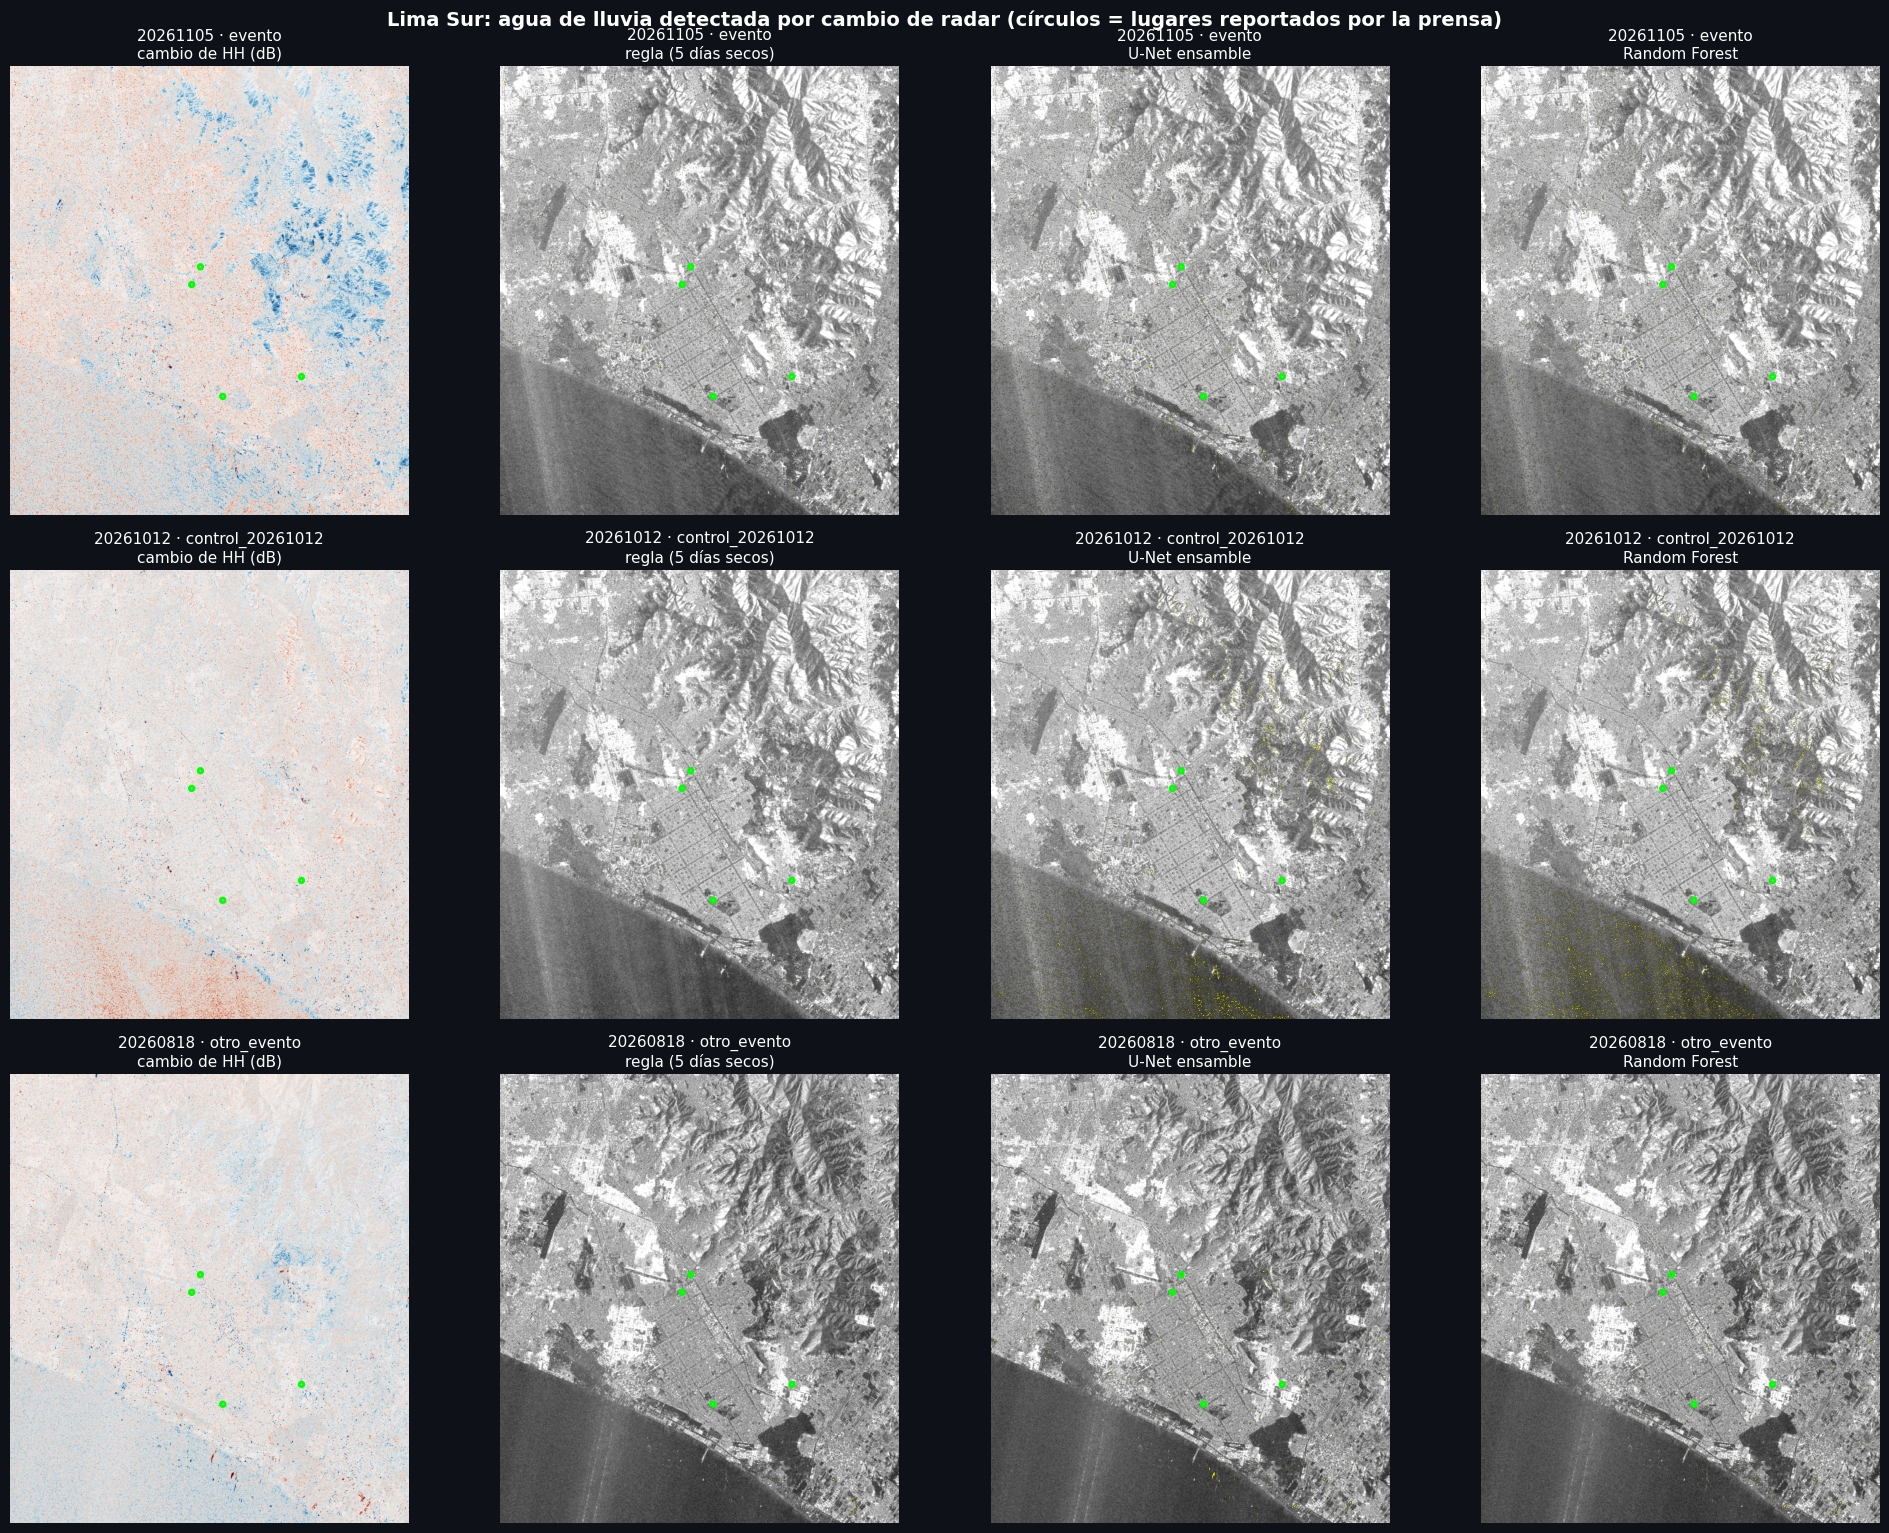

In [11]:
mejor_dl = max([n for n in MODELOS if n.startswith("U-Net")], key=lambda n: RES_[(RES_.modelo == n) & (RES_.caso == "evento")].IoU.iloc[0])
mejor_ml = max([n for n in MODELOS if not n.startswith("U-Net")], key=lambda n: RES_[(RES_.modelo == n) & (RES_.caso == "evento")].IoU.iloc[0])
print("mejor U-Net:", mejor_dl, "| mejor ML:", mejor_ml)
casos_mapa = ["evento"] + [c for c in R if c.startswith("control")][:1] + (["otro_evento"] if "otro_evento" in R else [])
fig, ejes = plt.subplots(len(casos_mapa), 4, figsize=(20, 5.2 * len(casos_mapa)), facecolor="#0e1117", squeeze=False)
for i, caso in enumerate(casos_mapa):
    fondo = FONDO[caso].astype("float32")
    d = R[caso]["d"][SUR].astype("float32"); etc = R[caso]["et"][SUR]
    paneles = [("cambio de HH (dB)", np.ma.masked_invalid(d), "RdBu", -8, 8),
               ("regla (5 días secos)", np.ma.masked_where(etc != 1, etc), "autumn", 0, 1),
               (mejor_dl, None, "autumn", 0, 1), (mejor_ml, None, "autumn", 0, 1)]
    for j, (titulo, capa, cmap, vmin, vmax) in enumerate(paneles):
        ax = ejes[i, j]; ax.imshow(fondo, cmap="gray", vmin=-25, vmax=5)
        if capa is None:
            p = np.nan_to_num(PROB[(titulo, caso)][SUR]) >= UMBRAL[titulo]
            capa = np.ma.masked_where(~p, p.astype(float))
        ax.imshow(capa, cmap=cmap, vmin=vmin, vmax=vmax, alpha=0.9)
        for lugar, lat, lon in NOTICIAS:
            rr, cc = a_pixel(lat, lon); rr -= SUR[0].start; cc -= SUR[1].start
            ax.add_patch(plt.Circle((cc, rr), 20, fill=False, color="lime", lw=2))
        ax.set_title(f"{CASOS[caso]['fecha']} · {caso}\n{titulo}", color="white", fontsize=11); ax.axis("off")
fig.suptitle("Lima Sur: agua de lluvia detectada por cambio de radar (círculos = lugares reportados por la prensa)", color="white", fontsize=14, weight="bold")
plt.tight_layout(); plt.savefig(SALIDA / "figuras/02_mapas_lima_sur.png", dpi=120, facecolor=fig.get_facecolor()); plt.show()

## 7. Exportar resultados para los mapas interactivos
Se guardan en GeoTIFF (recorte de Lima Sur): el radar de fondo, el cambio de HH, la etiqueta de la regla, y la probabilidad y la detección del **mejor modelo**. El mejor modelo es el de mayor IoU en las zonas de prueba del 5 de noviembre, con menos falsas alarmas en los controles.

In [12]:
GEO = SALIDA / "geotiff"; GEO.mkdir(exist_ok=True)
ev = RES_[RES_.caso == "evento"].set_index("modelo")
ctrl = RES_[RES_.caso.str.startswith("control")].groupby("modelo")["% área marcada (Lima Sur)"].mean()
ev["falsa_alarma_controles_%"] = ctrl
ev["puntaje"] = ev.IoU - 0.01 * ev["falsa_alarma_controles_%"].fillna(0)
MEJOR = ev.puntaje.idxmax()
print("mejor modelo:", MEJOR, "| IoU prueba 5 nov:", round(ev.loc[MEJOR, "IoU"], 3), "| % marcado en controles:", round(ev.loc[MEJOR, "falsa_alarma_controles_%"], 2))
display(ev[["IoU", "F1", "Precision", "Recall", "% área marcada (Lima Sur)", "falsa_alarma_controles_%"]].sort_values("IoU", ascending=False).round(3))

alto, ancho = SUR[0].stop - SUR[0].start, SUR[1].stop - SUR[1].start
T_SUR = TRANSF * rasterio.Affine.translation(SUR[1].start, SUR[0].start)
def guardar(nombre, arr, dtype, nodata):
    perfil = dict(driver="GTiff", height=alto, width=ancho, count=1, dtype=dtype, crs=PERFIL["crs"], transform=T_SUR,
                  nodata=nodata, compress="deflate")
    with rasterio.open(GEO / f"{nombre}.tif", "w", **perfil) as f:
        f.write(arr.astype(dtype), 1)

META = {"mejor_modelo": MEJOR, "umbral": float(UMBRAL[MEJOR]), "res_m": float(RES), "casos": {}, "noticias": []}
for caso in R:
    fch = CASOS[caso]["fecha"]
    guardar(f"fondo_{caso}", FONDO[caso].astype("float32"), "float32", np.nan)
    guardar(f"cambio_{caso}", R[caso]["d"][SUR].astype("float32"), "float32", np.nan)
    guardar(f"regla_{caso}", R[caso]["et"][SUR], "uint8", 255)
    p = PROB[(MEJOR, caso)][SUR].astype("float32")
    guardar(f"prob_{caso}", p, "float32", np.nan)
    guardar(f"deteccion_{caso}", np.where(np.isfinite(p), (p >= UMBRAL[MEJOR]).astype("uint8"), 255), "uint8", 255)
    fila = RES_[(RES_.modelo == MEJOR) & (RES_.caso == caso)].iloc[0]
    META["casos"][caso] = {"fecha": fch, "IoU": float(fila.IoU), "pct_marcado": float(fila["% área marcada (Lima Sur)"]),
                           "pct_regla": float(fila["% área marcada por la regla (Lima Sur)"]), "prensa": fila["lugares de prensa marcados"]}
for _, r in VIAB_PUNTOS.iterrows():
    lat, lon = [(la, lo) for n, la, lo in NOTICIAS if n == r.lugar][0]
    META["noticias"].append({"caso": r.caso, "lugar": r.lugar, "lat": lat, "lon": lon, "cambio_db": float(r["cambio (dB)"]),
                             "percentil": float(r["percentil en la ciudad"])})
json.dump(META, open(GEO / "meta.json", "w"), ensure_ascii=False, indent=2)
import shutil
shutil.make_archive(str(SALIDA / "resultados_final"), "zip", SALIDA, ".")
for p in sorted(GEO.iterdir()):
    print(f"  {p.name} ({p.stat().st_size / 1e6:.1f} MB)")

mejor modelo: U-Net ensamble | IoU prueba 5 nov: 0.245 | % marcado en controles: 0.93


,IoU,F1,Precision,Recall,% área marcada (Lima Sur),falsa_alarma_controles_%
modelo,,,,,,
U-Net ensamble,0.245,0.393,0.337,0.473,1.956,0.926
U-Net vgg19_bn,0.242,0.389,0.316,0.507,2.313,1.198
U-Net mobilenet_v2,0.239,0.386,0.323,0.479,2.014,0.944
Random Forest,0.237,0.383,0.332,0.452,1.903,0.833
U-Net efficientnet-b0,0.236,0.382,0.315,0.484,2.143,1.139
Regresión logística,0.236,0.381,0.297,0.531,2.482,1.246
HistGradientBoosting,0.233,0.378,0.281,0.575,2.856,1.366
U-Net resnet34,0.231,0.375,0.304,0.489,2.257,0.983
XGBoost,0.226,0.368,0.300,0.476,2.205,1.072


  cambio_control_20260713.tif (34.2 MB)
  cambio_control_20261012.tif (34.3 MB)
  cambio_evento.tif (34.1 MB)
  cambio_otro_evento.tif (34.3 MB)
  deteccion_control_20260713.tif (0.1 MB)
  deteccion_control_20261012.tif (0.3 MB)
  deteccion_evento.tif (0.2 MB)
  deteccion_otro_evento.tif (0.2 MB)
  fondo_control_20260713.tif (30.5 MB)
  fondo_control_20261012.tif (31.2 MB)
  fondo_evento.tif (31.2 MB)
  fondo_otro_evento.tif (30.5 MB)
  meta.json (0.0 MB)
  prob_control_20260713.tif (29.9 MB)
  prob_control_20261012.tif (30.4 MB)
  prob_evento.tif (30.4 MB)
  prob_otro_evento.tif (30.0 MB)
  regla_control_20260713.tif (0.5 MB)
  regla_control_20261012.tif (0.5 MB)
  regla_evento.tif (0.5 MB)
  regla_otro_evento.tif (0.5 MB)


## 8. Cómo leer los resultados
- **Viabilidad:** si en el 5 de noviembre los lugares de la prensa tienen percentil bajo (se oscurecieron más que casi toda la ciudad) y en el control no, hay señal real de agua de lluvia.
- **IoU en zonas de prueba:** mide si el modelo, con **una sola** imagen previa, reproduce lo que la regla obtiene con 5 días secos.
- **Controles secos:** un buen modelo marca casi nada en un día sin lluvia. Si marca lo mismo que en el evento, está detectando ruido y no lluvia.
- **Otro evento (18 ago):** el pase fue ~2 días después de la lluvia, así que se espera menos agua. Sirve para ver si el modelo generaliza a otra órbita.
- **Limitación:** la etiqueta es automática. La validación independiente son los controles y los lugares de la prensa.